# Dataset exploration: Watkins Marine Mammal Sound Database (cleaned)

Run after `Preprocess.ipynb`. Figures are saved to `outputs/exploration/`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import config
print("data root:", config.DATA_ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, torch
OUT = config.PROJECT_ROOT / "outputs" / "exploration"; OUT.mkdir(parents=True, exist_ok=True)
clean = pd.read_csv(config.ANNOT_DIR / "audio_annotations.csv")
excluded = pd.read_csv(config.ANNOT_DIR / "excluded.csv")
index = pd.read_csv(config.OLD_DIR / "index.csv")
print(f"download: {index.zip_species.notna().sum()} wav files | clean: {len(clean)} clips, "
      f"{clean.category.nunique()} species, {clean.recording.nunique()} recordings | excluded: {len(excluded)}")

data root: D:\UNI&WORK\Watkins


download: 15248 wav files | clean: 14098 clips, 44 species, 378 recordings | excluded: 1151


## 1. What was removed and why

reason
label_conflict       535
multi_species        299
too_short            272
species_not_in_44     31
duplicate_audio       13
no_audio               1
Name: count, dtype: int64

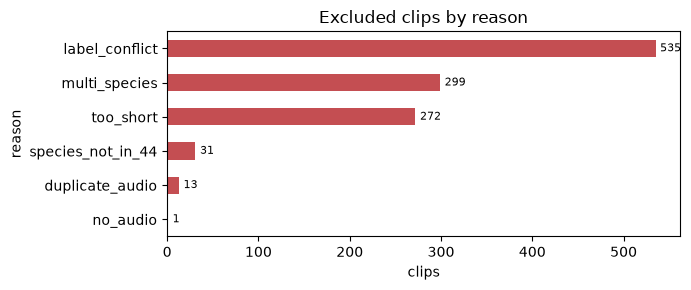

In [2]:
ex = excluded.reason.value_counts()
fig, ax = plt.subplots(figsize=(7, 3)); ex.sort_values().plot.barh(ax=ax, color="#C44E52")
for i, v in enumerate(ex.sort_values()): ax.text(v + 5, i, str(v), va="center", fontsize=8)
ax.set(title="Excluded clips by reason", xlabel="clips"); fig.tight_layout(); fig.savefig(OUT / "excluded_by_reason.png", dpi=150)
ex

## 2. Clips and recordings per species

Strong imbalance: Killer whale alone has ~2,600 clips, several species have < 50. A *recording* = first 5 characters of the filename.

category,TucuxiDolphin,Heaviside_sDolphin,DuskyDolphin,Dall_sPorpoise,Boutu_AmazonRiverDolphin,LeopardSeal,SouthernRightWhale,LongBeaked(Pacific)CommonDolphin,MelonHeadedWhale,Rough_ToothedDolphin,...,SpinnerDolphin,WeddellSeal,Beluga_WhiteWhale,Short_Finned(Pacific)PilotWhale,HumpbackWhale,Long_FinnedPilotWhale,NorthernRightWhale,Fin_FinbackWhale,SpermWhale,KillerWhale
clips,12,14,27,31,30,15,49,68,93,98,...,474,131,147,603,604,1095,485,570,1102,2644
recordings,1,1,1,1,2,2,2,2,2,2,...,11,11,12,12,14,18,22,41,57,65


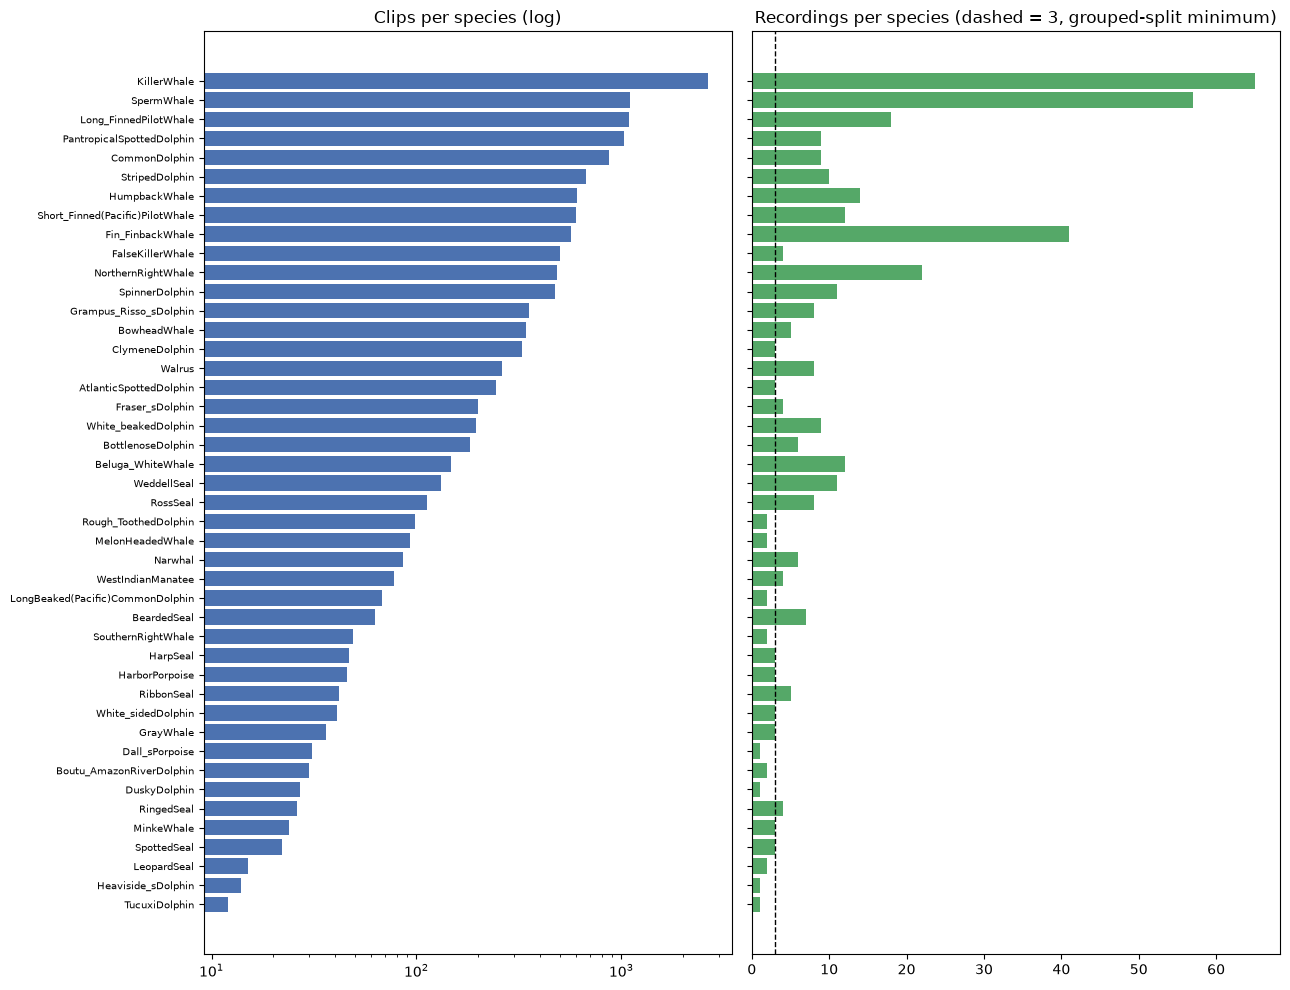

In [3]:
per = clean.groupby("category").agg(clips=("filename", "size"), recordings=("recording", "nunique")).sort_values("clips")
fig, ax = plt.subplots(1, 2, figsize=(13, 10), sharey=True)
ax[0].barh(per.index, per.clips, color="#4C72B0"); ax[0].set(xscale="log", title="Clips per species (log)")
ax[1].barh(per.index, per.recordings, color="#55A868"); ax[1].axvline(3, color="k", ls="--", lw=1)
ax[1].set(title="Recordings per species (dashed = 3, grouped-split minimum)")
for a in ax: a.tick_params(axis="y", labelsize=7)
fig.tight_layout(); fig.savefig(OUT / "clips_recordings_per_species.png", dpi=150)
per.sort_values("recordings").T

## 3. Clip duration

Most clips are 1–3 s. The model sees the first ~4.65 s (400 frames); shorter clips are zero-padded, longer ones cropped.

median 1.84 s | <1 s: 20% | >4.65 s (cropped): 13% | max 1456 s


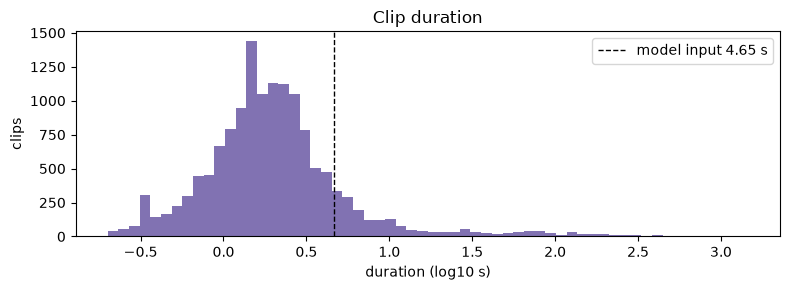

In [4]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(np.log10(clean.duration_sec), bins=60, color="#8172B2")
ax.axvline(np.log10(4.65), color="k", ls="--", lw=1, label="model input 4.65 s"); ax.legend()
ax.set(xlabel="duration (log10 s)", ylabel="clips", title="Clip duration")
fig.tight_layout(); fig.savefig(OUT / "duration_hist.png", dpi=150)
d = clean.duration_sec
print(f"median {d.median():.2f} s | <1 s: {(d<1).mean():.0%} | >4.65 s (cropped): {(d>4.65).mean():.0%} | max {d.max():.0f} s")

## 4. Sample rates

Recordings span 7 decades of equipment: from 320 Hz to 192 kHz. Everything is resampled to 44 kHz for the spectrograms.
Low-rate clips (< 4 kHz) contain no high-frequency content at all; > 96 kHz clips lose everything above 22 kHz
(relevant for dolphin clicks/whistles). The sample rate is strongly tied to species and recording, so it is a possible shortcut.

{'ok': 11554, 'high': 1874, 'low': 670}


,min,median,max,nunique
category,,,,
KillerWhale,10240,21900.0,45400,7
StripedDolphin,47600,81600.0,192000,7
ClymeneDolphin,41600,166600.0,192000,8
Short_Finned(Pacific)PilotWhale,20000,80000.0,100000,8
Walrus,2560,10000.0,40960,8
NorthernRightWhale,1280,10200.0,20480,8
CommonDolphin,40000,43900.0,192000,9
Beluga_WhiteWhale,10000,40000.0,81920,9
Long_FinnedPilotWhale,23500,166600.0,166600,11


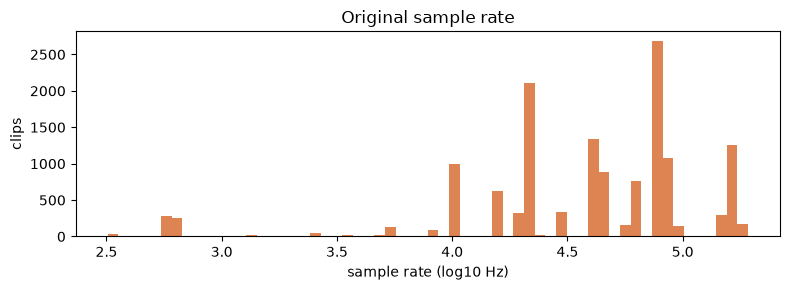

In [5]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(np.log10(clean.sample_rate), bins=60, color="#DD8452")
ax.set(xlabel="sample rate (log10 Hz)", ylabel="clips", title="Original sample rate")
fig.tight_layout(); fig.savefig(OUT / "sample_rate_hist.png", dpi=150)
print(clean.sr_flag.value_counts().to_dict())
clean.groupby("category").sample_rate.agg(["min", "median", "max", "nunique"]).sort_values("nunique").tail(10)

## 5. Recording year

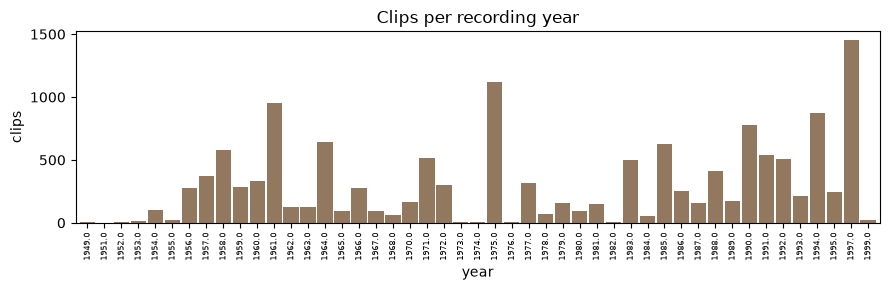

In [6]:
fig, ax = plt.subplots(figsize=(9, 3))
clean.year.value_counts().sort_index().plot.bar(ax=ax, color="#937860", width=0.9)
ax.set(title="Clips per recording year", ylabel="clips"); ax.tick_params(axis="x", labelsize=6)
fig.tight_layout(); fig.savefig(OUT / "year_hist.png", dpi=150)

## 6. The two splits

In [7]:
for name, d in [("main (44 species, clip-level)", config.MAIN_SPLIT_DIR), ("grouped (34 species, by recording)", config.GROUPED_SPLIT_DIR)]:
    parts = {s: pd.read_csv(d / f"{s}.csv") for s in ["train", "val", "test"]}
    n = sum(len(p) for p in parts.values())
    print(name, {s: f"{len(p)} ({len(p)/n:.0%})" for s, p in parts.items()},
          "| recordings shared train/test:", len(set(parts["train"].recording) & set(parts["test"].recording)))
print("left out of grouped split:", pd.read_csv(config.GROUPED_SPLIT_DIR / "species_left_out.csv").iloc[:, 0].tolist())

main (44 species, clip-level) {'train': '9868 (70%)', 'val': '2115 (15%)', 'test': '2115 (15%)'} | recordings shared train/test: 297
grouped (34 species, by recording) {'train': '9502 (70%)', 'val': '2102 (15%)', 'test': '2057 (15%)'} | recordings shared train/test: 0
left out of grouped split: ['Boutu_AmazonRiverDolphin', 'Dall_sPorpoise', 'DuskyDolphin', 'Heaviside_sDolphin', 'LeopardSeal', 'LongBeaked(Pacific)CommonDolphin', 'MelonHeadedWhale', 'Rough_ToothedDolphin', 'SouthernRightWhale', 'TucuxiDolphin']


## 7. Example spectrograms (model input)

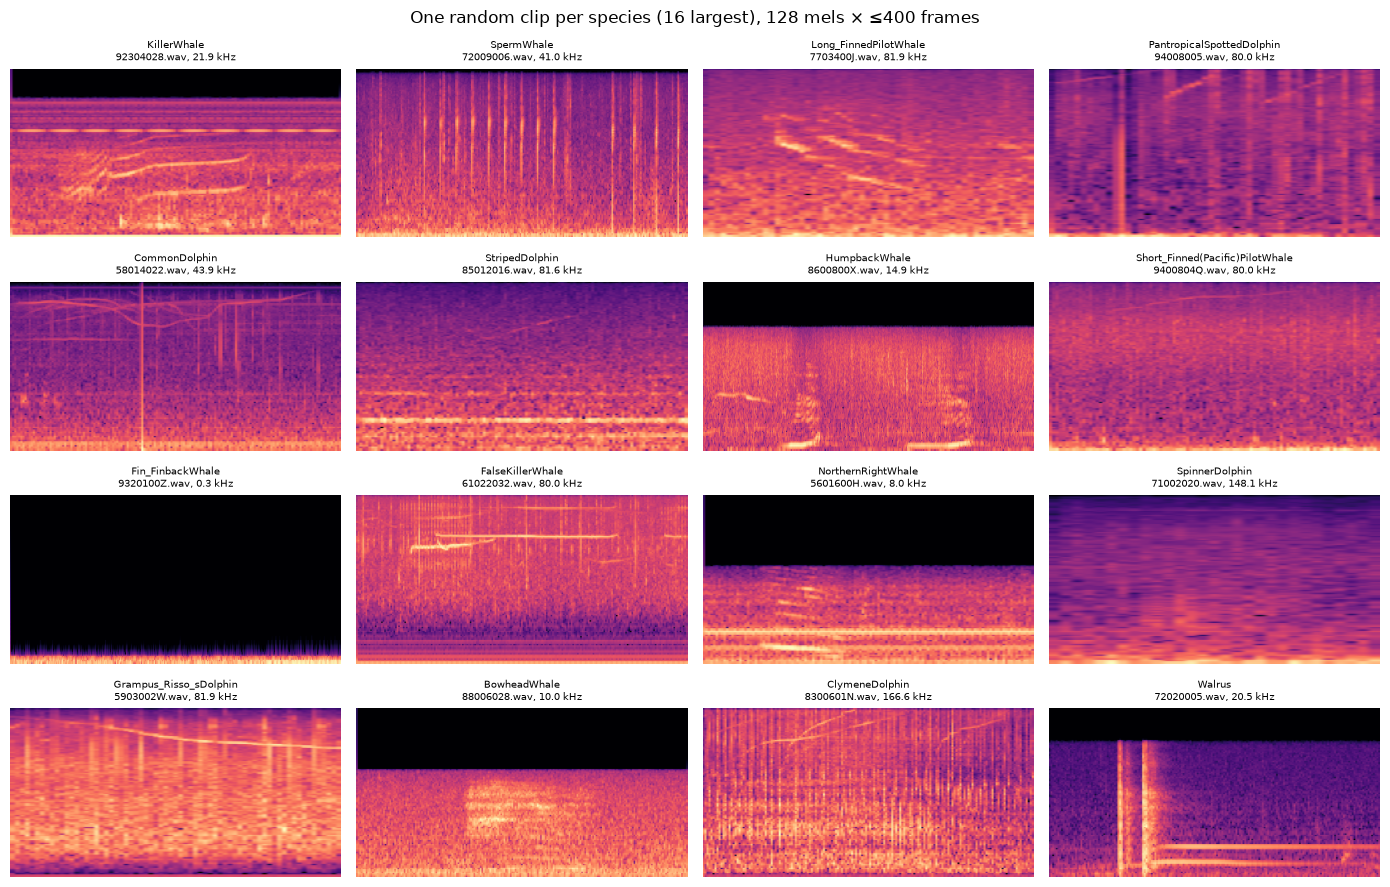

In [8]:
species = per.sort_values("clips", ascending=False).index[:16]
fig, axes = plt.subplots(4, 4, figsize=(14, 9))
rng = np.random.default_rng(0)
for ax, sp in zip(axes.flat, species):
    row = clean[clean.category == sp].sample(1, random_state=1).iloc[0]
    t = torch.load(config.SPEC_DIR / sp / f"{row.filename}.norm.pt", weights_only=True)[0, :, :400]
    ax.imshow(t, origin="lower", aspect="auto", cmap="magma")
    ax.set_title(f"{sp}\n{row.filename}, {row.sample_rate/1000:.1f} kHz", fontsize=7); ax.axis("off")
fig.suptitle("One random clip per species (16 largest), 128 mels × ≤400 frames"); fig.tight_layout()
fig.savefig(OUT / "example_spectrograms.png", dpi=150)